# Import Library

In [15]:
import json
import math
import random
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.rasterizer import render_sketch

In [16]:
# Import Progress Generator
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
from src.progressive_generator import (
    generate_partial_sketch,
    COMPLETION_LEVELS
)
print("Progressive generator berhasil di-import!")

Progressive generator berhasil di-import!


# Project Configuration

In [17]:
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "sampled"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
VISUALIZATION_DIR = PROJECT_ROOT / "outputs" / "visualizations"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("Report directory:", REPORT_DIR)

Project root: d:\SMT 5\Deep Learning\EarlySketch
Dataset directory: d:\SMT 5\Deep Learning\EarlySketch\data\sampled
Report directory: d:\SMT 5\Deep Learning\EarlySketch\outputs\reports


# Checking Dataset
check apakah dataset berhasil diunduh semua

In [18]:
dataset_files = sorted(DATA_DIR.glob("*.ndjson"))

if not dataset_files:
    raise FileNotFoundError(
        f"Tidak ditemukan file NDJSON di: {DATA_DIR}"
    )

print(f"Total kategori ditemukan: {len(dataset_files)}")
print("\nDaftar kategori:")

for file_path in dataset_files:
    file_size_mb = file_path.stat().st_size / (1024 ** 2)
    print(
        f"- {file_path.stem:<15} "
        f"{file_size_mb:.2f} MB"
    )

Total kategori ditemukan: 10

Daftar kategori:
- airplane        2.54 MB
- bicycle         2.27 MB
- bird            2.09 MB
- car             2.87 MB
- cat             2.30 MB
- dog             2.50 MB
- fish            1.58 MB
- flower          2.21 MB
- house           1.70 MB
- tree            2.28 MB


# Ndjson Data Loader
karena Ndjson terlalu besar kita membaca menggunakan json.load()

In [19]:
def load_ndjson(file_path: Path):
    """
    Read NDJSON records line by line.

    Parameters
    ----------
    file_path : Path
        Location of NDJSON file.

    Yields
    ------
    dict
        One JSON record at a time.
    """
    with file_path.open("r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                record = json.loads(line)
                if not isinstance(record, dict):
                    raise ValueError("Record bukan JSON object")
                yield record
            except (json.JSONDecodeError, ValueError) as error:
                print(
                    f"[WARNING] {file_path.name}, "
                    f"line {line_number}: {error}"
                )

# Validation Struktur
Menghitung :
1. total strokes
2. total points
3. valid strokes
4. dan check apakah record memiliki struktur yang dapat diproses

In [20]:
def analyze_drawing(drawing):
    """
    Validate Quick, Draw! drawing structure
    and calculate stroke-level statistics.
    """
    if not isinstance(drawing, list) or len(drawing) == 0:
        return {
            "is_valid": False,
            "total_strokes": 0,
            "valid_strokes": 0,
            "total_points": 0,
            "validation_message": "Empty or invalid drawing"
        }

    total_strokes = len(drawing)
    valid_strokes = 0
    total_points = 0

    for stroke in drawing:
        if not isinstance(stroke, (list, tuple)) or len(stroke) < 2:
            continue
        x_coords = stroke[0]
        y_coords = stroke[1]
        if not isinstance(x_coords, list):
            continue
        if not isinstance(y_coords, list):
            continue
        if len(x_coords) == 0 or len(x_coords) != len(y_coords):
            continue
        try:
            x = np.asarray(x_coords, dtype=np.float64)
            y = np.asarray(y_coords, dtype=np.float64)
            if not np.all(np.isfinite(x)):
                continue
            if not np.all(np.isfinite(y)):
                continue
        except (TypeError, ValueError):
            continue

        valid_strokes += 1
        total_points += len(x_coords)

    is_valid = (
        valid_strokes == total_strokes
        and total_points > 0
    )

    return {
        "is_valid": is_valid,
        "total_strokes": total_strokes,
        "valid_strokes": valid_strokes,
        "total_points": total_points,
        "validation_message": (
            "Valid" if is_valid else "Invalid stroke detected"
        )
    }


# Explore All Dataset

In [21]:
dataset_records = []
drawings = {}

for file_path in dataset_files:
    category = file_path.stem
    print(f"Processing category: {category}")
    for record in load_ndjson(file_path):
        drawing = record.get("drawing")
        key_id = record.get("key_id")
        drawing_info = analyze_drawing(drawing)
        drawing_id = f"{category}_{key_id}"

        metadata = {
            "drawing_id": drawing_id,
            "key_id": key_id,
            "category": category,
            "word": record.get("word"),
            "recognized": record.get("recognized"),
            "timestamp": record.get("timestamp"),
            **drawing_info
        }

        dataset_records.append(metadata)
        # Store original stroke coordinates
        drawings[drawing_id] = drawing

df = pd.DataFrame(dataset_records)
print("\nExploration completed!")
print("Total metadata:", len(df))
print("Total drawings:", len(drawings))
print("Total categories:", df["category"].nunique())

display(df.head())


Processing category: airplane
Processing category: bicycle
Processing category: bird
Processing category: car
Processing category: cat
Processing category: dog
Processing category: fish
Processing category: flower
Processing category: house
Processing category: tree

Exploration completed!
Total metadata: 5000
Total drawings: 5000
Total categories: 10


,drawing_id,key_id,category,word,recognized,timestamp,is_valid,total_strokes,valid_strokes,total_points,validation_message
0,airplane_5290311376961536,5290311376961536,airplane,airplane,True,2017-03-06 19:58:28.01762 UTC,True,11,11,192,Valid
1,airplane_4587020284329984,4587020284329984,airplane,airplane,True,2017-01-27 03:23:20.45964 UTC,True,4,4,400,Valid
2,airplane_4703562825203712,4703562825203712,airplane,airplane,True,2017-03-28 12:55:38.12811 UTC,True,3,3,174,Valid
3,airplane_5442522853670912,5442522853670912,airplane,airplane,True,2017-03-17 16:20:05.64505 UTC,True,5,5,188,Valid
4,airplane_5401917024894976,5401917024894976,airplane,airplane,True,2017-03-16 17:50:29.55602 UTC,True,3,3,211,Valid


# Category Distribution & Plot
jika sampling berhasil harusnya akan mengahasilkan 500 gambar

,category,total_images,valid_images,avg_strokes,avg_points,min_points,max_points
0,airplane,500,500,4.59,247.20,17,975
1,bicycle,500,500,8.01,216.69,54,1269
2,bird,500,500,6.68,203.31,22,848
3,car,500,500,5.25,267.33,69,707
4,cat,500,500,9.84,221.47,51,624
5,dog,500,500,6.73,237.40,44,564
6,fish,500,500,3.36,143.20,40,524
7,flower,500,500,4.08,203.47,18,618
8,house,500,500,3.68,169.45,44,615
9,tree,500,500,3.84,216.84,31,1004


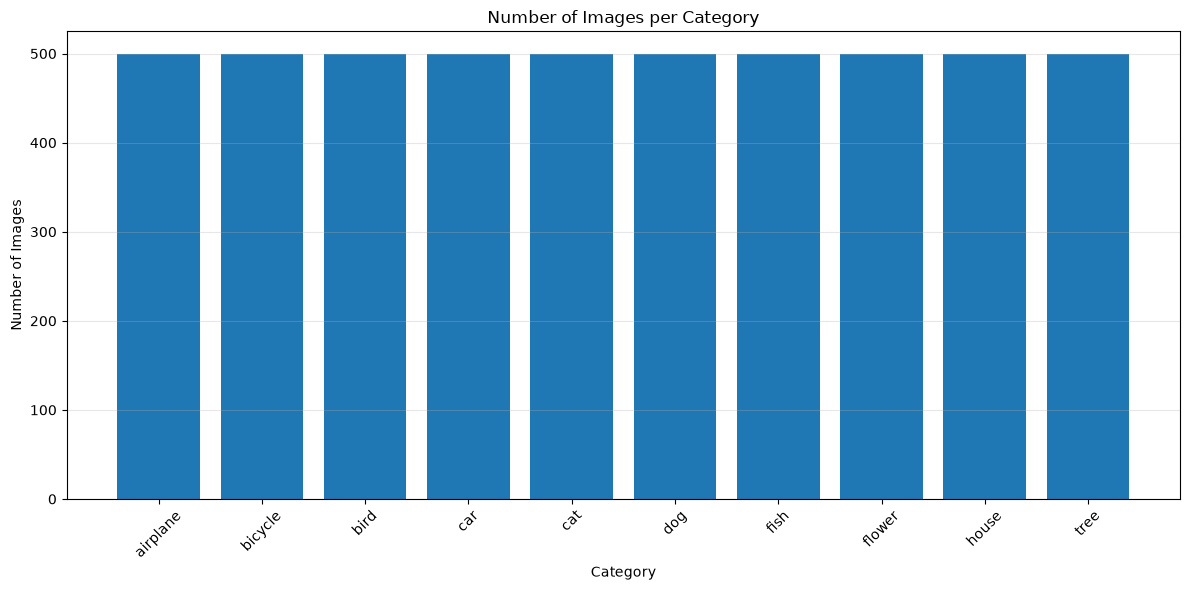

In [22]:
category_summary = (
    df.groupby("category")
    .agg(
        total_images=("key_id", "count"),
        valid_images=("is_valid", "sum"),
        avg_strokes=("total_strokes", "mean"),
        avg_points=("total_points", "mean"),
        min_points=("total_points", "min"),
        max_points=("total_points", "max")
    )
    .round(2)
    .reset_index()
)

display(category_summary)

plt.figure(figsize=(12, 6))
plt.bar(
    category_summary["category"],
    category_summary["total_images"]
)
plt.title("Number of Images per Category")
plt.xlabel("Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    VISUALIZATION_DIR / "category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Analysis of the number of strokes, points and plot
membantu kita apakah sebagian kategeri cenderung memiliki jumlah stroke yang lebih sedikit atau lebih banyak.

Valid images: 5000
Invalid images: 0

Stroke statistics:


count    5000.000000
mean        5.607000
std         3.814376
min         1.000000
25%         3.000000
50%         5.000000
75%         7.000000
max        39.000000
Name: total_strokes, dtype: float64


Point statistics:


count    5000.000000
mean      212.637200
std       104.978894
min        17.000000
25%       140.000000
50%       191.000000
75%       262.000000
max      1269.000000
Name: total_points, dtype: float64


Stroke distribution:


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
airplane,500.0,4.59,2.87,1.0,3.0,4.0,6.0,25.0
bicycle,500.0,8.01,3.60,1.0,5.0,7.0,10.0,27.0
bird,500.0,6.68,3.98,1.0,4.0,6.0,9.0,30.0
car,500.0,5.25,3.26,1.0,3.0,4.0,6.0,27.0
cat,500.0,9.84,3.90,1.0,7.0,9.0,12.0,29.0
dog,500.0,6.73,3.79,1.0,4.0,7.0,9.0,24.0
fish,500.0,3.36,2.19,1.0,2.0,3.0,4.0,16.0
flower,500.0,4.08,2.73,1.0,3.0,3.0,5.0,23.0
house,500.0,3.68,2.29,1.0,2.0,3.0,5.0,16.0


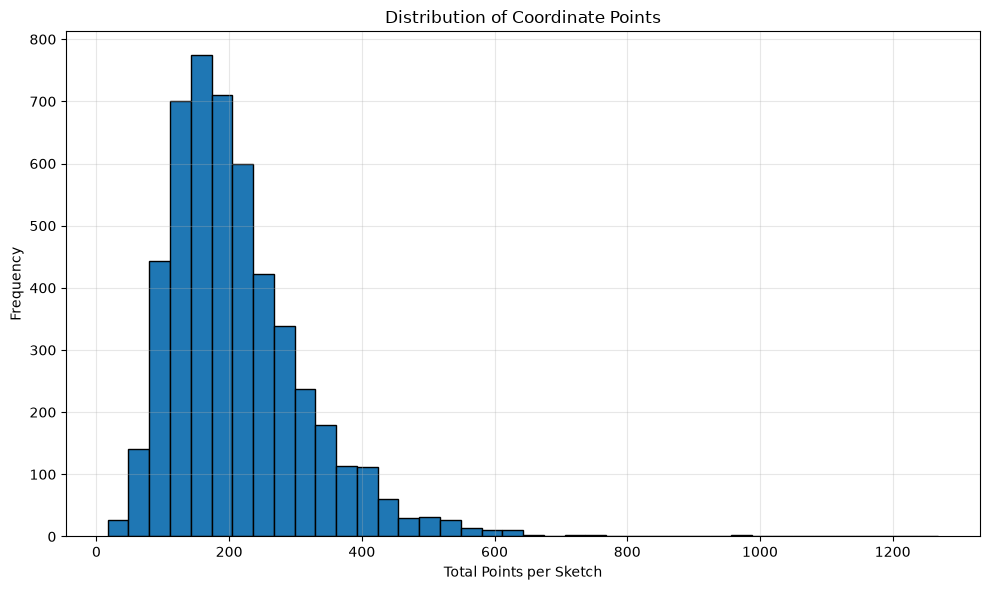

In [23]:
valid_df = df[df["is_valid"]].copy()
print("Valid images:", len(valid_df))
print("Invalid images:", len(df) - len(valid_df))
print("\nStroke statistics:")
display(valid_df["total_strokes"].describe())
print("\nPoint statistics:")
display(valid_df["total_points"].describe())
print("\nStroke distribution:")
display(
    valid_df.groupby("category")["total_strokes"]
    .describe()
    .round(2)
)

plt.figure(figsize=(10, 6))
plt.hist(
    valid_df["total_points"],
    bins=40,
    edgecolor="black"
)
plt.title("Distribution of Coordinate Points")
plt.xlabel("Total Points per Sketch")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    VISUALIZATION_DIR / "point_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Show some image

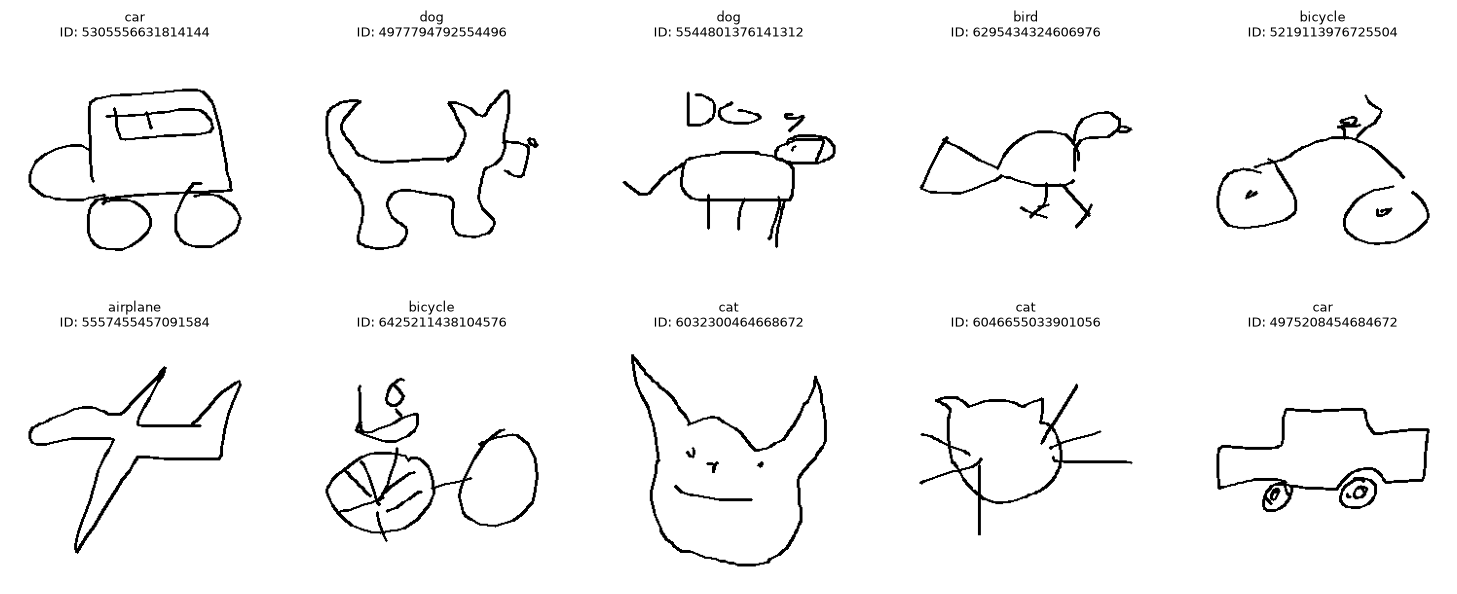

In [ ]:
def visualize_samples(df, drawings, n_samples=10):
    valid_samples = df[df["is_valid"]]
    selected = valid_samples.sample(
        n=min(n_samples, len(valid_samples)),
        random_state=42
    )

    columns = 5
    rows = math.ceil(len(selected) / columns)
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(15, 3 * rows)
    )
    axes = np.array(axes).reshape(-1)
    for ax, (_, sample) in zip(axes, selected.iterrows()):
        drawing_id = sample["drawing_id"]
        drawing = drawings[drawing_id]
        image = render_sketch(
            drawing,
            image_size=256
        )
        ax.imshow(image)
        ax.set_title(
            f'{sample["category"]}\nID: {sample["key_id"]}',
            fontsize=9
        )
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(
        VISUALIZATION_DIR / "sample_sketches.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# Execute visualization
visualize_samples(
    df,
    drawings,
    n_samples=10
)

# Save result exploration

In [25]:
df.to_csv(
    REPORT_DIR / "dataset_metadata.csv",
    index=False
)
category_summary.to_csv(
    REPORT_DIR / "category_summary.csv",
    index=False
)
# Overall dataset statistics
overall_summary = pd.DataFrame([{
    "total_images": len(df),
    "total_categories": df["category"].nunique(),
    "valid_images": int(df["is_valid"].sum()),
    "invalid_images": int((~df["is_valid"]).sum()),
    "duplicate_key_ids": int(df["key_id"].duplicated().sum()),
    "average_strokes": round(valid_df["total_strokes"].mean(), 2),
    "average_points": round(valid_df["total_points"].mean(), 2)
}])
overall_summary.to_csv(
    REPORT_DIR / "overall_summary.csv",
    index=False
)
print("Reports successfully saved!")
print("Location:", REPORT_DIR)

Reports successfully saved!
Location: d:\SMT 5\Deep Learning\EarlySketch\outputs\reports


# Check Partial Sketch & Visualization

20%: 2 dari 12 strokes
40%: 4 dari 12 strokes
60%: 7 dari 12 strokes
80%: 9 dari 12 strokes
100%: 12 dari 12 strokes


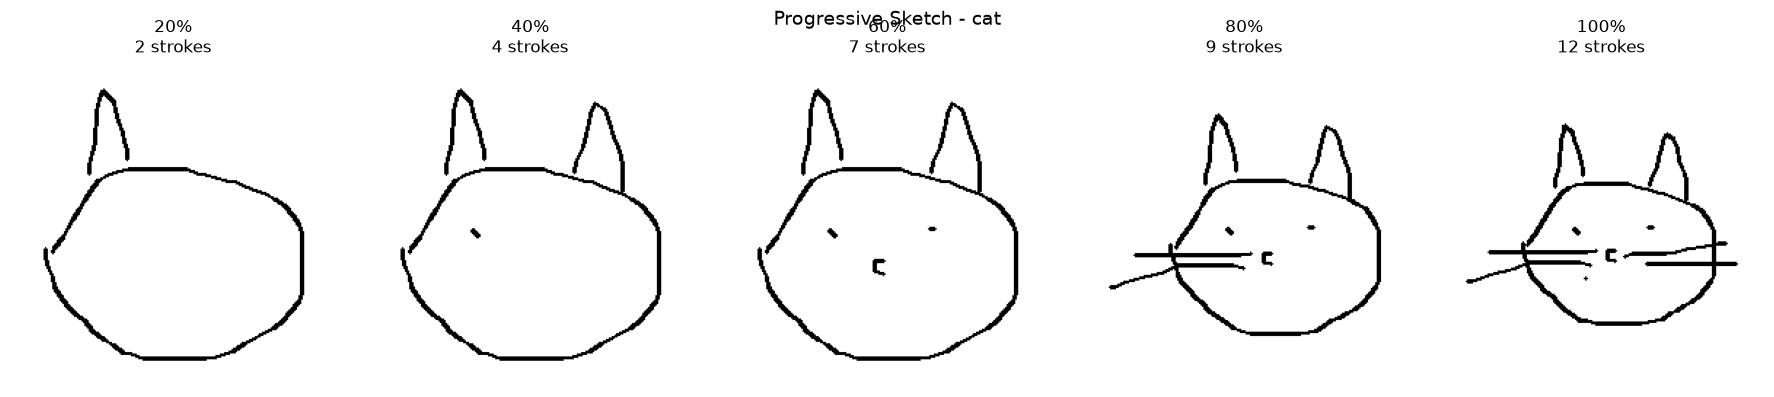

In [26]:
sample = df[
    (df["category"] == "cat") &
    (df["is_valid"])
].iloc[0]

# Mengambil data stroke asli
drawing = drawings[sample["drawing_id"]]

# Menghasilkan partial sketch
for percentage in COMPLETION_LEVELS:
    partial_drawing = generate_partial_sketch(
        drawing,
        percentage
    )
    print(
        f"{percentage}%: "
        f"{len(partial_drawing)} dari {len(drawing)} strokes"
    )

def visualize_progressive_sketch(drawing, category):
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    for ax, percentage in zip(axes, COMPLETION_LEVELS):
        partial_drawing = generate_partial_sketch(
            drawing,
            percentage
        )
        image = render_sketch(
            partial_drawing,
            image_size=224
        )
        ax.imshow(image)
        ax.set_title(
            f"{percentage}%\n"
            f"{len(partial_drawing)} strokes"
        )
        ax.axis("off")
    fig.suptitle(
        f"Progressive Sketch - {category}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

visualize_progressive_sketch(
    drawing,
    sample["category"]
)